# Tutorial: building quantum circuits with `qsim`

This notebook walks through the simulator from a single qubit up to Grover's search. Each section shows the code first, then explains what the statevector tells us.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qsim import Circuit
from qsim.algorithms import bell_state, ghz_state, teleportation, grover
np.set_printoptions(precision=3, suppress=True)

## 1. One qubit in superposition

A Hadamard gate takes |0⟩ to (|0⟩ + |1⟩)/√2, so each outcome has probability 1/2.

In [2]:
c = Circuit(1).h(0)
print(c)
print('statevector:', c.statevector())
print('counts:', c.sample(1000, seed=0))

q0: ─[H]──
statevector: [0.707+0.j 0.707+0.j]
counts: {'0': 473, '1': 527}


## 2. Entanglement: the Bell state

H followed by CNOT gives (|00⟩ + |11⟩)/√2. The two qubits always agree when measured.

In [3]:
bell = bell_state()
print(bell)
print(bell.statevector())
print(bell.sample(1000, seed=0))

q0: ─[H]───●───
q1: ───────⊕───
[0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]
{'00': 473, '11': 527}


## 3. How a gate is applied

The state of *n* qubits is stored as a tensor of shape (2, 2, …, 2). Applying a *k*-qubit gate is one `np.tensordot` over the target axes, which avoids ever building a full 2ⁿ × 2ⁿ matrix.

In [4]:
ghz = ghz_state(5)
print(ghz)
p = ghz.probabilities()
print({format(i, '05b'): round(float(v), 3) for i, v in enumerate(p) if v > 1e-9})

q0: ─[H]───●──────────────────
q1: ───────⊕────●─────────────
q2: ────────────⊕────●────────
q3: ─────────────────⊕────●───
q4: ──────────────────────⊕───
{'00000': 0.5, '11111': 0.5}


## 4. Quantum teleportation

We send RY(θ)RZ(φ)|0⟩ from qubit 0 to qubit 2. Measurements and classical corrections are replaced by controlled gates (deferred measurement). Tracing out qubits 0 and 1 should leave qubit 2 in the original state.

In [5]:
theta, phi = 1.2, 0.7
psi = teleportation(theta, phi).statevector().reshape(2, 2, 2)
rho_q2 = np.einsum('abi,abj->ij', psi, psi.conj())
target = Circuit(1).ry(theta, 0).rz(phi, 0).statevector()
print('received:\n', rho_q2)
print('expected:\n', np.outer(target, target.conj()))
print('fidelity:', np.real(target.conj() @ rho_q2 @ target))

received:
 [[0.681+0.j  0.356-0.3j]
 [0.356+0.3j 0.319+0.j ]]
expected:
 [[0.681-0.j  0.356-0.3j]
 [0.356+0.3j 0.319-0.j ]]
fidelity: 0.9999999999999994


## 5. Grover's search

With 4 qubits there are 16 states. Grover needs about π/4·√16 ≈ 3 iterations to amplify the marked state.

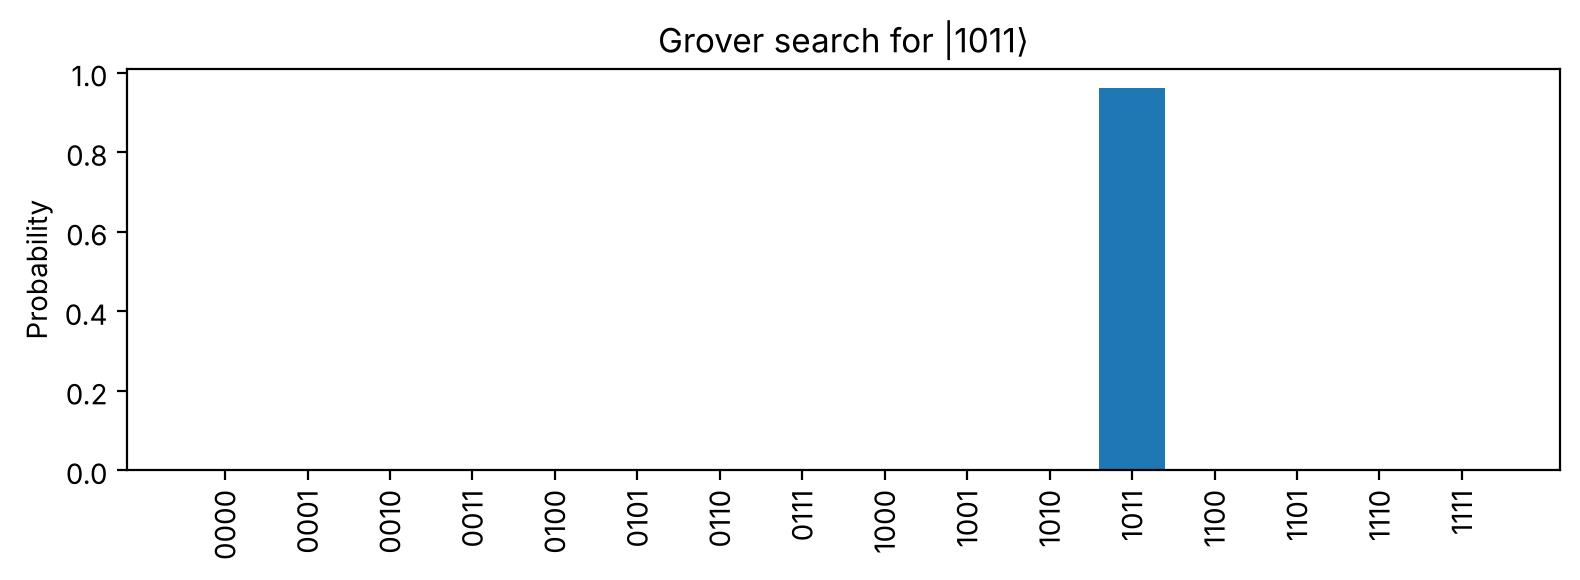

P(1011) = 0.9613


In [6]:
g = grover(4, '1011')
p = g.probabilities()
labels = [format(i, '04b') for i in range(16)]
plt.figure(figsize=(8, 3))
plt.bar(labels, p)
plt.xticks(rotation=90)
plt.ylabel('Probability')
plt.title('Grover search for |1011⟩')
plt.tight_layout()
plt.savefig('grover.png', dpi=150)
plt.show()
print('P(1011) =', round(p[int('1011', 2)], 4))

## 6. Checking against Qiskit

The test suite in `tests/` rebuilds every circuit in Qiskit and compares statevectors to 10⁻¹⁰. Run it with `pytest`.